# OmniGeo: Phase 1 — Nationwide County Benchmark & 150-County Archetype Discovery

> **Objective**: Define a mathematically representative, transparent sample of US counties/regions across **5 macro-regions** (Northeast, Midwest, South/Southeast, Southwest, Northwest) using open public datasets from **data.gov**, **US Census**, **USDA ERS**, and **MIT Election Lab**.
> 
> Rather than canvassing all ~3,143 US counties (which is computationally and storage-wise prohibitive for subsequent multi-terabyte satellite and flight feeds), we mathematically select **30 distinct, archetypal counties per macro-region (150 counties total, representing ~4.8% of all US counties)**. 
> 
> Each county is captured not as a crude bounding box, but as an **exact, high-precision irregular cartographic polygon** (US Census TIGER) and polyfilled with **Uber H3 hexagonal grid cells** for subsequent cross-domain association mining.

---

### Data Sources Merged:
1. **US Census Bureau Population & Migration (2020–2023)**: `co-est2023-alldata.csv`
2. **USDA Economic Research Service (ERS) RUCC 2023**: `2023-rural-urban-continuum-codes.csv` (Codes 1–9)
3. **US Census SAIPE 2022 (Small Area Income & Poverty)**: `est22all.txt` (Median household income, all-age poverty, child poverty)
4. **2020 Presidential Election Results**: County-level votes, percentages, margins
5. **MIT Election Data & Science Lab (MEDSL)**: 2012, 2016, 2020 presidential returns, turnout, and demographic shares
6. **Official US Census TIGER Cartographic Polygons**: True irregular county boundary shapes

In [1]:
import os
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# Ensure working directory is project root
if (Path.cwd() / "src").exists():
    PROJECT_ROOT = Path.cwd().resolve()
else:
    PROJECT_ROOT = Path.cwd().parent.resolve()
os.chdir(PROJECT_ROOT)
print(f"Working directory set to: {PROJECT_ROOT}")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

from omni.benchmark.builder import build_master_county_benchmark
from omni.selection.stratifier import select_nationwide_cohort
from omni.visualization.charts import (
    plot_national_landscape,
    plot_regional_pca_biplot,
    plot_county_fingerprint_radar,
    plot_political_swing_slopegraph,
    create_interactive_folium_map
)

# Display settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 20)
pd.set_option("display.precision", 3)
print("OmniGeo Analytics Environment Loaded Successfully.")

Working directory set to: /home/moose/git/omni


OmniGeo Analytics Environment Loaded Successfully.


## 1. Master County Benchmark Table Construction (~3,131 Counties)

We download, clean, and harmonize the public datasets across all US counties on their 5-digit FIPS code.

In [2]:
gdf_benchmark = build_master_county_benchmark()
print(f"Master benchmark table constructed: {gdf_benchmark.shape[0]} counties with {gdf_benchmark.shape[1]} attributes.")
gdf_benchmark[["fips", "county_name", "state_abbr", "macro_region", "pop_2023", "median_hh_income", "poverty_pct", "rucc_code", "dem_margin_2020"]].head(10)

Loading county cartographic boundary polygons...


Parsing Census SAIPE income & poverty...
Parsing USDA ERS 2023 Rural-Urban Continuum Codes...
Parsing Census population estimates & migration...
Parsing 2020 presidential election results...
Parsing MEDSL 2012/2016 elections & demographic context...
Harmonizing all attributes into master table...
Merged tabular records: 3144 counties
Final GeoDataFrame ready: 3131 counties with exact polygons.
Master benchmark table constructed: 3131 counties with 44 attributes.


,fips,county_name,state_abbr,macro_region,pop_2023,median_hh_income,poverty_pct,rucc_code,dem_margin_2020
0,01001,Autauga County,AL,South / Southeast,60342.0,70148.0,11.8,2,-0.444
1,01003,Baldwin County,AL,South / Southeast,253507.0,71704.0,12.4,3,-0.538
2,01005,Barbour County,AL,South / Southeast,24585.0,41151.0,26.7,6,-0.077
3,01007,Bibb County,AL,South / Southeast,21868.0,54309.0,20.0,1,-0.577
4,01009,Blount County,AL,South / Southeast,59816.0,60553.0,13.6,1,-0.800
5,01011,Bullock County,AL,South / Southeast,9897.0,35798.0,31.5,8,0.499
6,01013,Butler County,AL,South / Southeast,18382.0,41852.0,23.4,6,-0.157
7,01015,Calhoun County,AL,South / Southeast,116429.0,52772.0,18.5,3,-0.390
8,01017,Chambers County,AL,South / Southeast,34079.0,45563.0,21.0,6,-0.156
9,01019,Cherokee County,AL,South / Southeast,25666.0,52613.0,15.5,8,-0.728


In [3]:
# Summary statistics across core analytical metrics
summary_cols = [
    "pop_2023", "pop_density_sq_km", "median_hh_income", 
    "poverty_pct", "child_poverty_pct", "dem_margin_2020", 
    "swing_2012_2020", "turnout_rate_2020", "racial_diversity_index"
]
gdf_benchmark[summary_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
pop_2023,3131.0,105802.249,332550.245,43.000,10755.500,25944.000,68816.000,9.663e+06
pop_density_sq_km,3131.0,99.661,539.098,0.013,6.097,16.870,45.181,1.624e+04
median_hh_income,3131.0,63217.103,16247.070,28972.000,52465.500,60784.000,70496.000,1.676e+05
poverty_pct,3131.0,14.631,5.615,3.100,10.700,13.700,17.600,4.240e+01
child_poverty_pct,3131.0,19.437,8.384,2.400,13.400,18.200,24.100,8.870e+01
dem_margin_2020,3131.0,-0.316,0.320,-0.931,-0.565,-0.380,-0.129,8.675e-01
swing_2012_2020,3131.0,-0.105,0.127,-0.683,-0.186,-0.106,-0.026,3.754e-01
turnout_rate_2020,3131.0,0.661,0.119,0.200,0.588,0.659,0.732,1.000e+00
racial_diversity_index,3131.0,0.300,0.181,0.000,0.128,0.270,0.472,7.414e-01


## 2. Exploratory Data Analysis: The National Landscape

Let's examine how wealth, political lean, density, and 8-year political swings distribute across the 5 macro-regions.

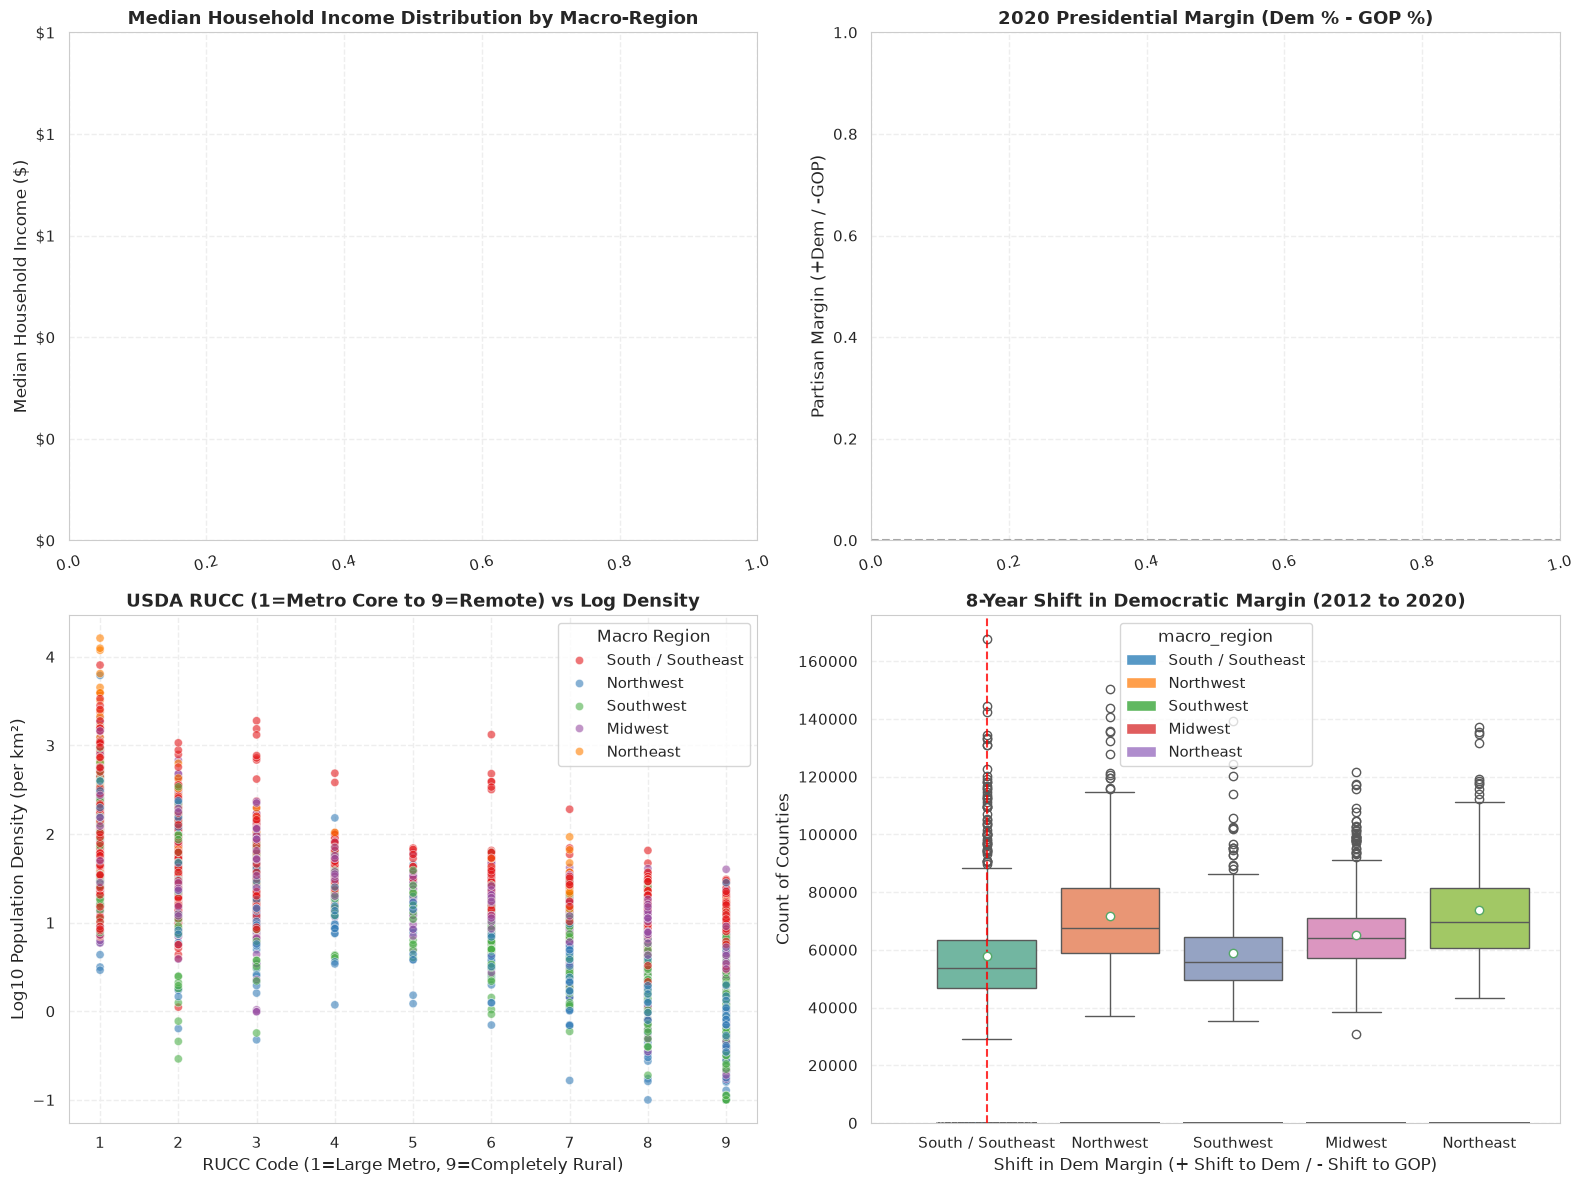

In [4]:
fig_national = plot_national_landscape(gdf_benchmark)
plt.show()

### Regional Feature Correlation Clustermap
How do demographic diversity, poverty, urban density, and political voting behavior correlate with one another across American counties?

<Figure size 1400x1100 with 0 Axes>

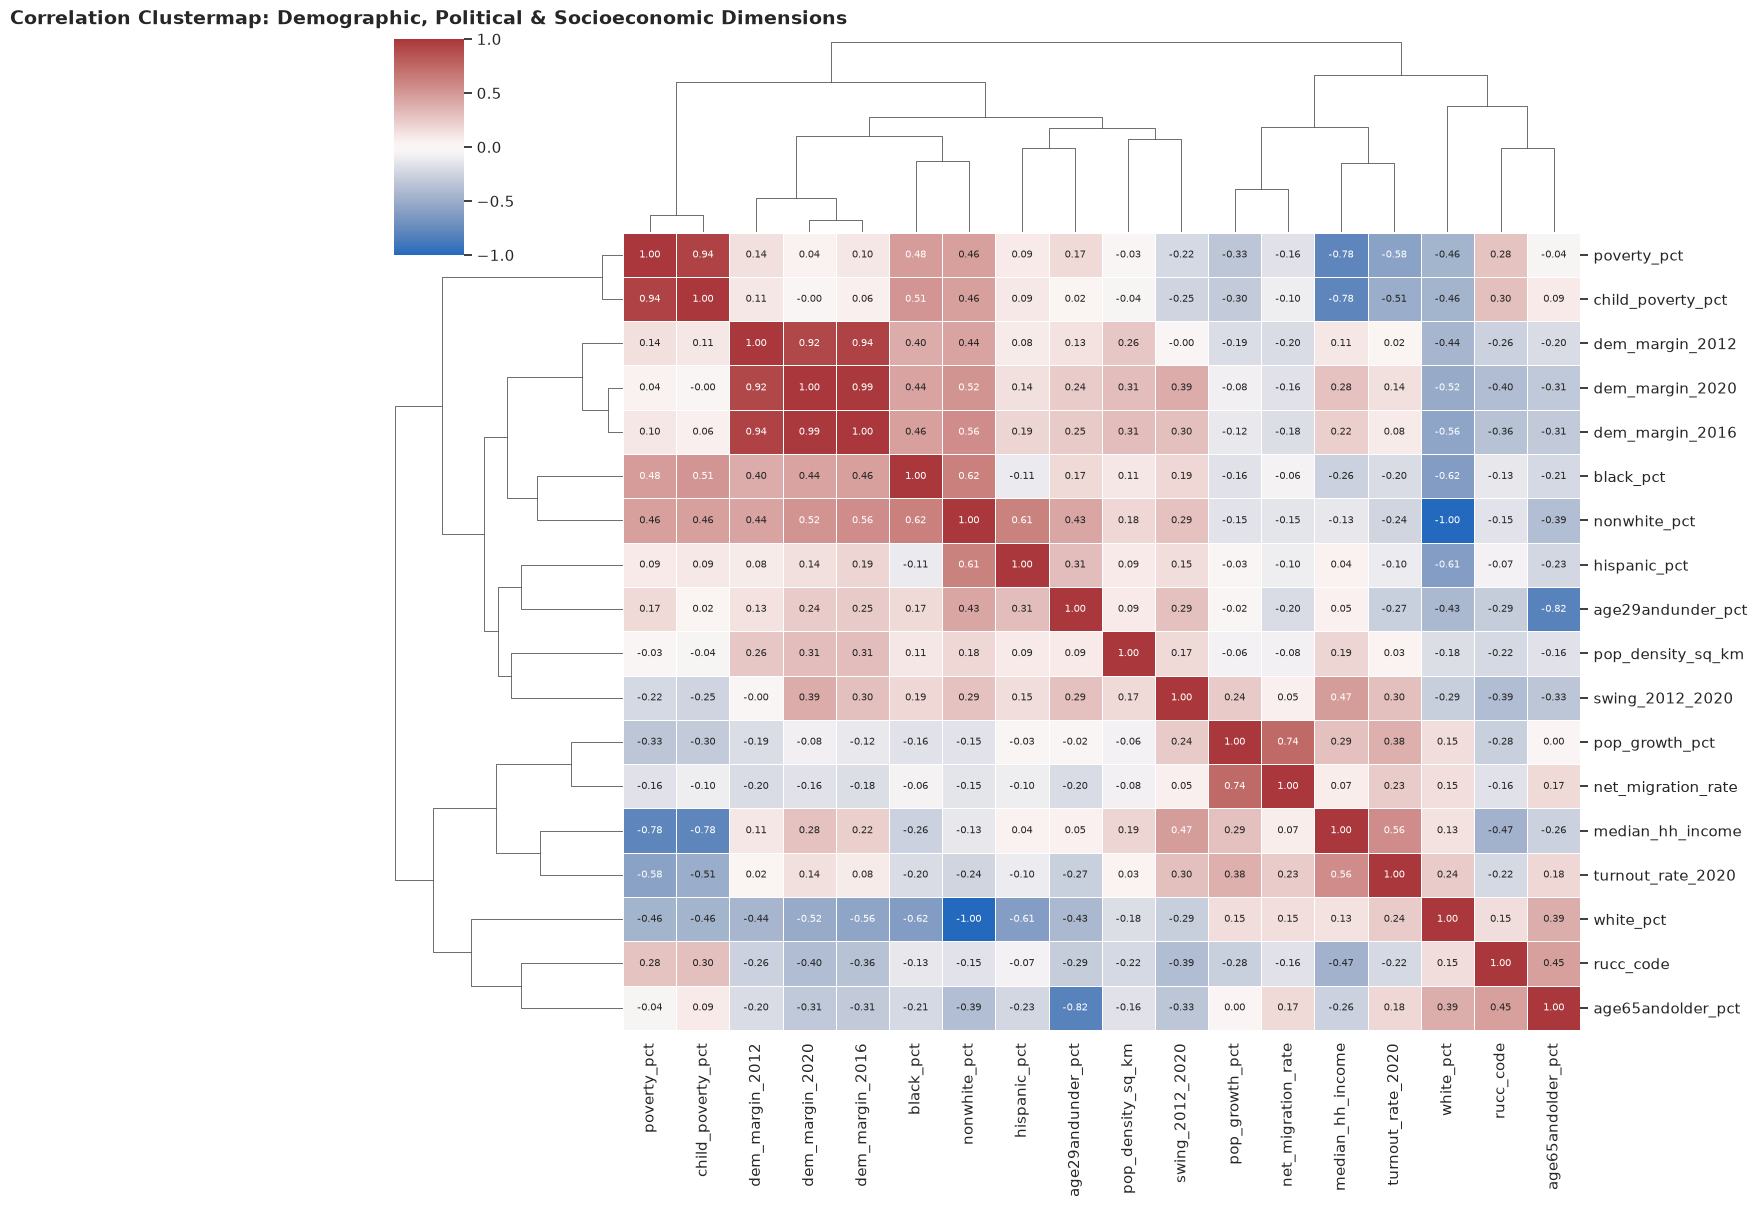

In [5]:
corr_cols = [
    "median_hh_income", "poverty_pct", "child_poverty_pct", "pop_growth_pct",
    "net_migration_rate", "pop_density_sq_km", "rucc_code", "dem_margin_2020",
    "dem_margin_2016", "dem_margin_2012", "swing_2012_2020", "turnout_rate_2020",
    "white_pct", "black_pct", "hispanic_pct", "nonwhite_pct", "age29andunder_pct", "age65andolder_pct"
]
corr_matrix = gdf_benchmark[corr_cols].corr()

plt.figure(figsize=(14, 11))
sns.clustermap(
    corr_matrix, cmap="vlag", center=0, annot=True, fmt=".2f",
    annot_kws={"size": 7.5}, figsize=(14, 12), linewidths=0.5
)
plt.title("Correlation Clustermap: Demographic, Political & Socioeconomic Dimensions", y=1.03, fontsize=14, fontweight="bold")
plt.show()

## 3. Mathematical Archetype Selection: 30 Counties per Macro-Region (150 Total)

For each of the 5 macro-regions, we execute:
1. Feature standardization across 15 socioeconomic, political, and density metrics.
2. Principal Component Analysis (PCA) to extract the primary orthogonal axes of regional variance.
3. **Regional Statistical Centroid**: Identifies the county closest to $(0,0,0,0)$ in PCA space (the purest statistical median).
4. **Stratified K-Medoids / K-Means ($k=29$)**: Identifies 29 contrasting archetypes across the regional spectrum (30 counties per region).
5. **H3 Hexagonal Polyfill**: Tessellates the interior of each county's irregular polygon into Uber H3 hexagons.

In [6]:
cohort_150 = select_nationwide_cohort(gdf_benchmark, n_per_region=30, h3_resolution=7)
print(f"Cohort generation complete: {len(cohort_150)} archetypal counties across 5 macro-regions.")
print("\nArchetypes discovered across the nation:")
cohort_150['archetype_label'].value_counts()


--- Stratifying Northeast (target: 30 counties) ---
Generating H3 polyfill hexagons for 30 counties in Northeast...

--- Stratifying Midwest (target: 30 counties) ---


Generating H3 polyfill hexagons for 30 counties in Midwest...

--- Stratifying South / Southeast (target: 30 counties) ---
Generating H3 polyfill hexagons for 30 counties in South / Southeast...

--- Stratifying Southwest (target: 30 counties) ---


Generating H3 polyfill hexagons for 30 counties in Southwest...

--- Stratifying Northwest (target: 30 counties) ---
Generating H3 polyfill hexagons for 30 counties in Northwest...

Successfully selected 150 archetypal counties across 5 macro-regions.
Cohort generation complete: 150 archetypal counties across 5 macro-regions.

Archetypes discovered across the nation:


archetype_label
University / Higher-Ed Innovation Hub                 24
Intensive Agricultural / Rural Heartland              21
Rapid-Growth Exurban / Sunbelt Corridor               19
Persistent-Poverty Distressed Rural                   18
Swing Bellwether / Polar Pivot County                 16
Mega-Urban Economic Center                            16
Affluent High-Tech / Executive Suburb                  9
Rural-Urban Transition Community                       9
Working-Class Industrial / Post-Industrial Hub         8
Regional Statistical Centroid (Archetypal Average)     5
Mid-Sized Regional Anchor Metro                        3
Diverse Majority-Minority Community                    2
Name: count, dtype: int64

---
## 4. Deep-Dive: Northeast (New England, NY, NJ, PA) (30 Counties)

Let's explore the 30 selected archetypes for **Northeast** through:
1. **Spatial & PCA Biplot**: Where the 30 counties sit in regional geography and latent space.
2. **Multi-Axis Radar Fingerprint**: Comparing contrasting archetypes across 8 dimensions.
3. **Political Swing Trajectory (2012 -> 2016 -> 2020)**: Tracking partisan polarization over 8 years.
4. **Archetype Selection Table**: Comprehensive metric profile for the 30 counties.

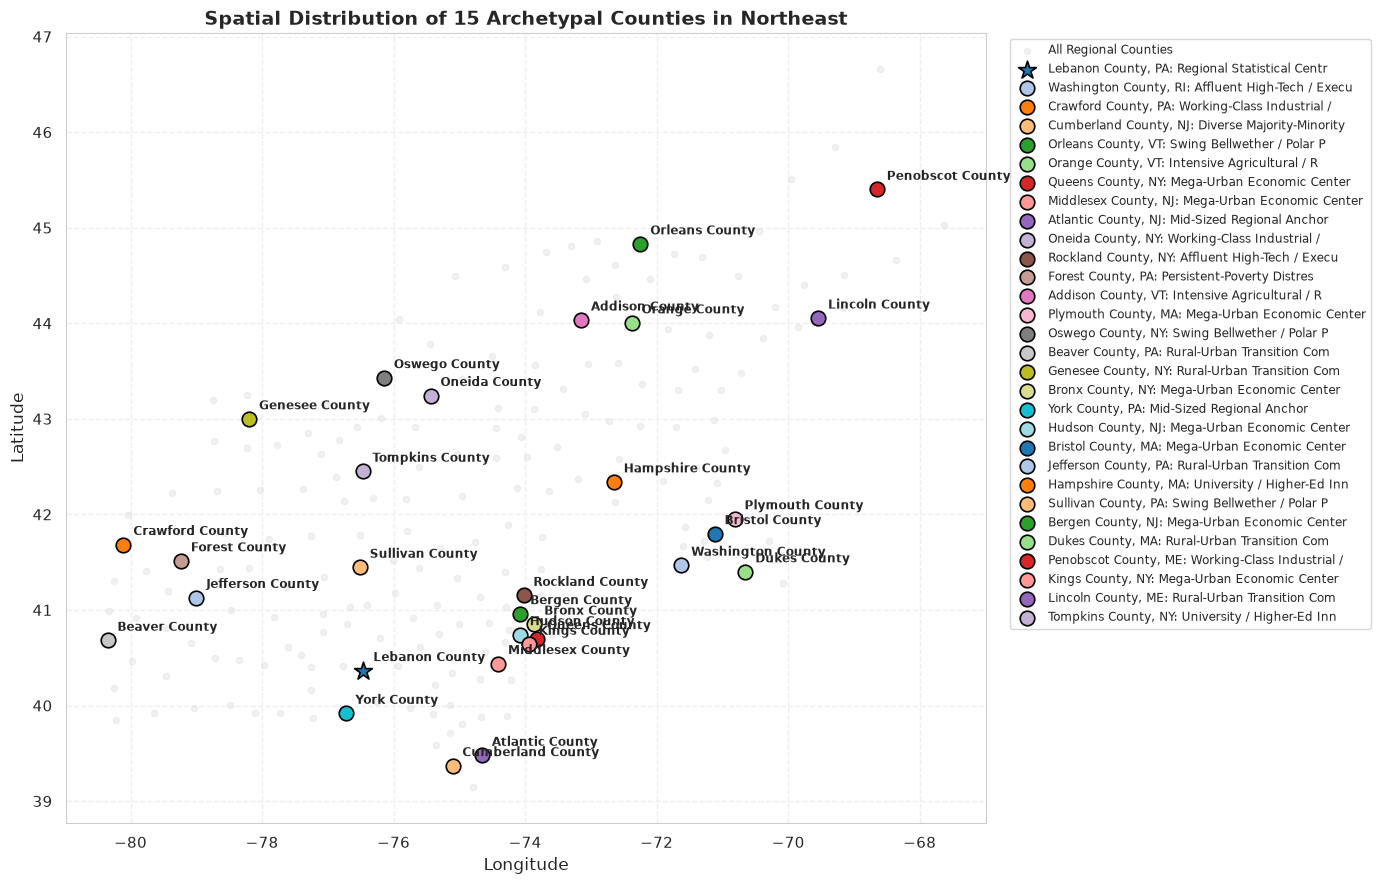

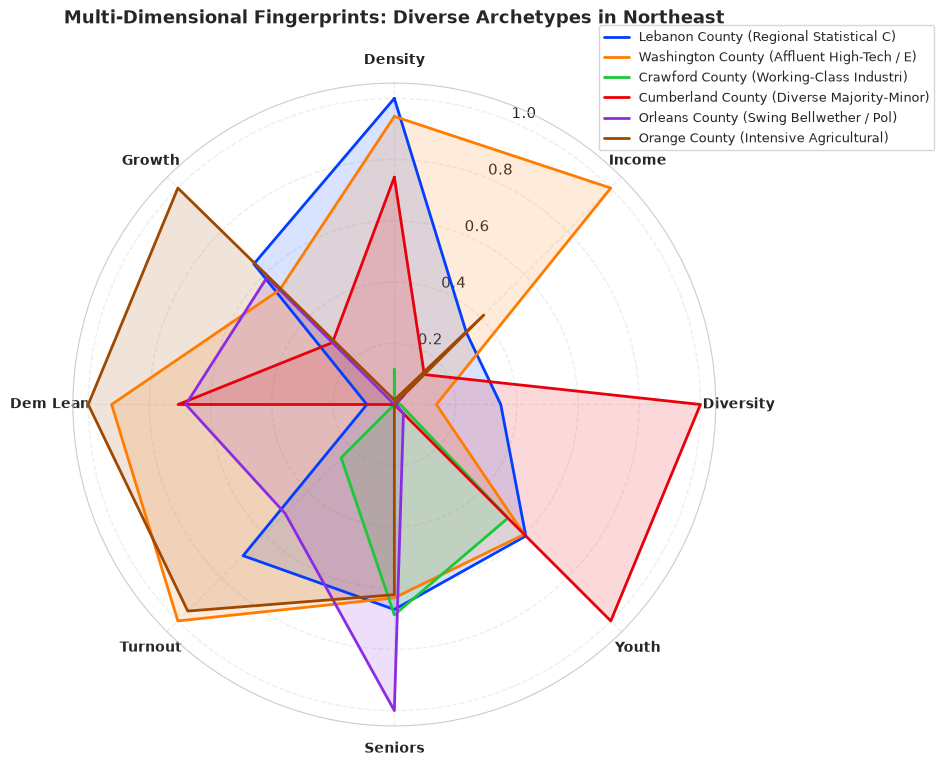

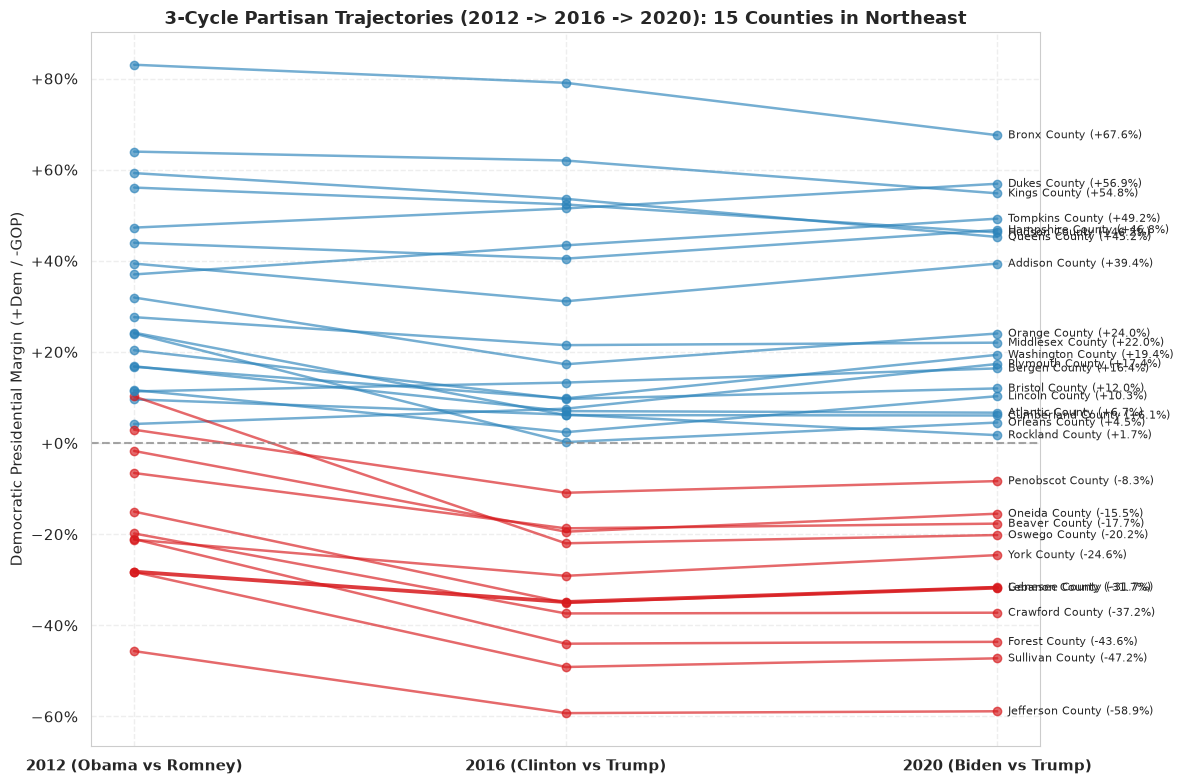

,fips,county_name,state_abbr,archetype_label,pop_2023,median_hh_income,poverty_pct,rucc_code,dem_margin_2020,swing_2012_2020,h3_cell_count
0,42075,Lebanon County,PA,Regional Statistical Centroid (Archetypal Aver...,1.443e+05,69490.0,11.3,3,-0.317,-0.035,1
1,44009,Washington County,RI,Affluent High-Tech / Executive Suburb,1.300e+05,99015.0,6.5,1,0.194,0.026,1
2,42039,Crawford County,PA,Working-Class Industrial / Post-Industrial Hub,8.200e+04,54774.0,13.9,4,-0.372,-0.174,1
3,34011,Cumberland County,NJ,Diverse Majority-Minority Community,1.523e+05,60892.0,15.5,3,0.061,-0.182,1
4,50019,Orleans County,VT,Swing Bellwether / Polar Pivot County,2.752e+04,56818.0,13.8,9,0.045,-0.195,1
...,...,...,...,...,...,...,...,...,...,...,...
25,25007,Dukes County,MA,Rural-Urban Transition Community,2.082e+04,89136.0,8.2,7,0.569,0.096,1
26,23019,Penobscot County,ME,Working-Class Industrial / Post-Industrial Hub,1.553e+05,60761.0,14.6,3,-0.083,-0.113,1
27,36047,Kings County,NY,Mega-Urban Economic Center,2.561e+06,73244.0,19.8,1,0.548,-0.092,1
28,23015,Lincoln County,ME,Rural-Urban Transition Community,3.651e+04,72657.0,9.1,8,0.103,-0.013,1


In [7]:
reg_cohort = cohort_150[cohort_150["macro_region"] == "Northeast"].copy()

# 1. Spatial Biplot
fig_biplot = plot_regional_pca_biplot(gdf_benchmark, reg_cohort, "Northeast")
plt.show()

# 2. Multi-Axis Radar Fingerprint
fig_radar = plot_county_fingerprint_radar(reg_cohort, "Northeast")
plt.show()

# 3. Political Swing Slopegraph (2012 -> 2016 -> 2020)
fig_slope = plot_political_swing_slopegraph(reg_cohort, "Northeast")
plt.show()

# 4. Archetype Profile Table
table_cols = [
    "fips", "county_name", "state_abbr", "archetype_label", 
    "pop_2023", "median_hh_income", "poverty_pct", "rucc_code", 
    "dem_margin_2020", "swing_2012_2020", "h3_cell_count"
]
reg_cohort[table_cols].reset_index(drop=True)

---
## 4. Deep-Dive: Midwest (Great Lakes & Plains) (30 Counties)

Let's explore the 30 selected archetypes for **Midwest** through:
1. **Spatial & PCA Biplot**: Where the 30 counties sit in regional geography and latent space.
2. **Multi-Axis Radar Fingerprint**: Comparing contrasting archetypes across 8 dimensions.
3. **Political Swing Trajectory (2012 -> 2016 -> 2020)**: Tracking partisan polarization over 8 years.
4. **Archetype Selection Table**: Comprehensive metric profile for the 30 counties.

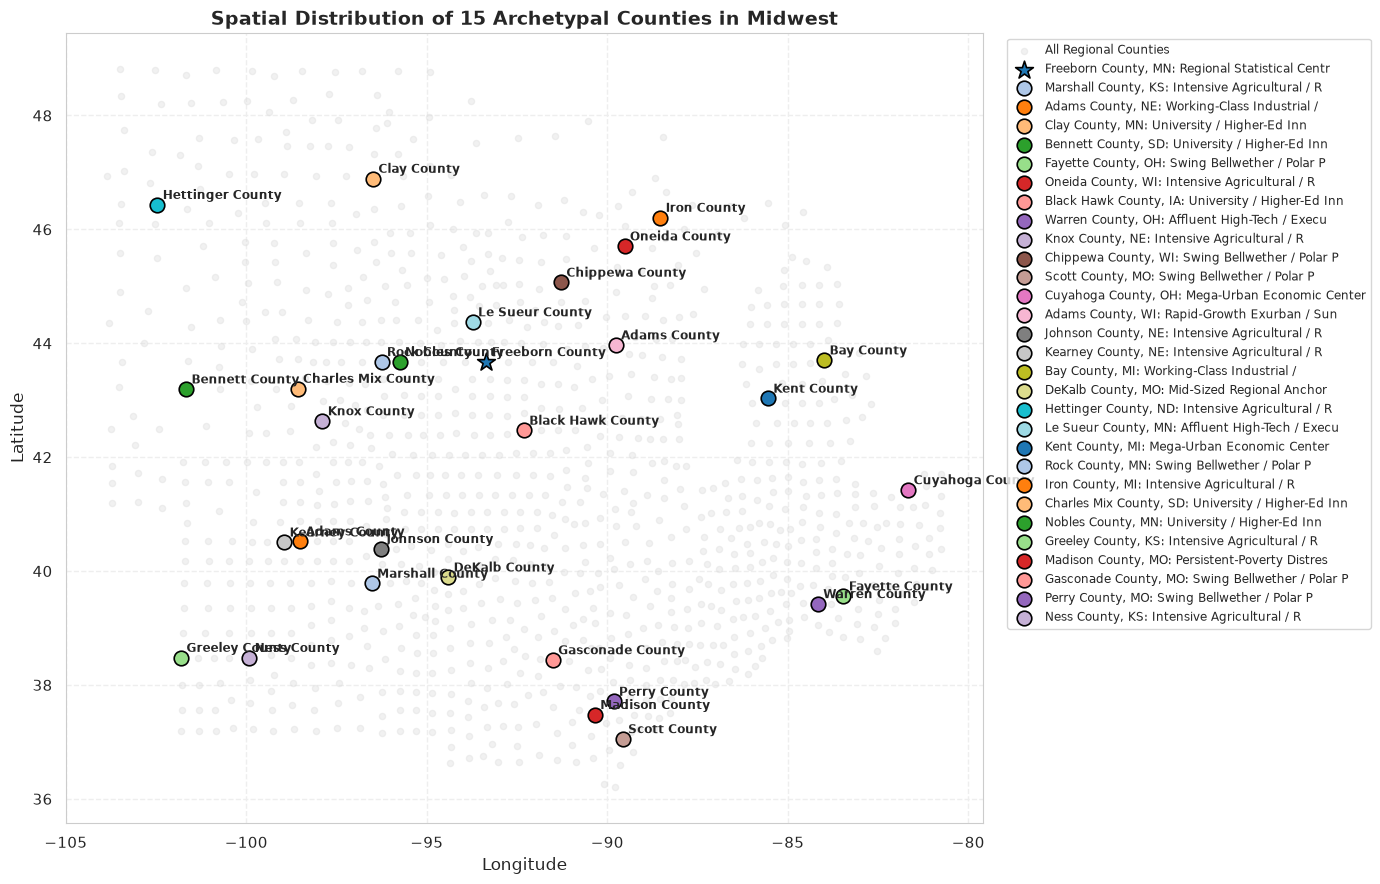

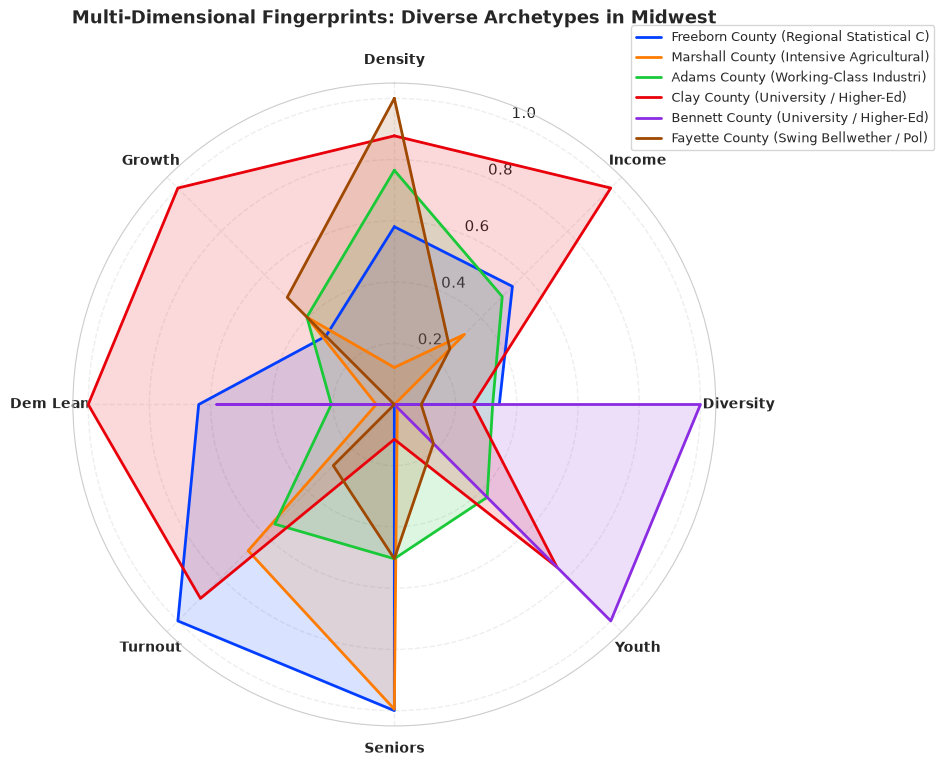

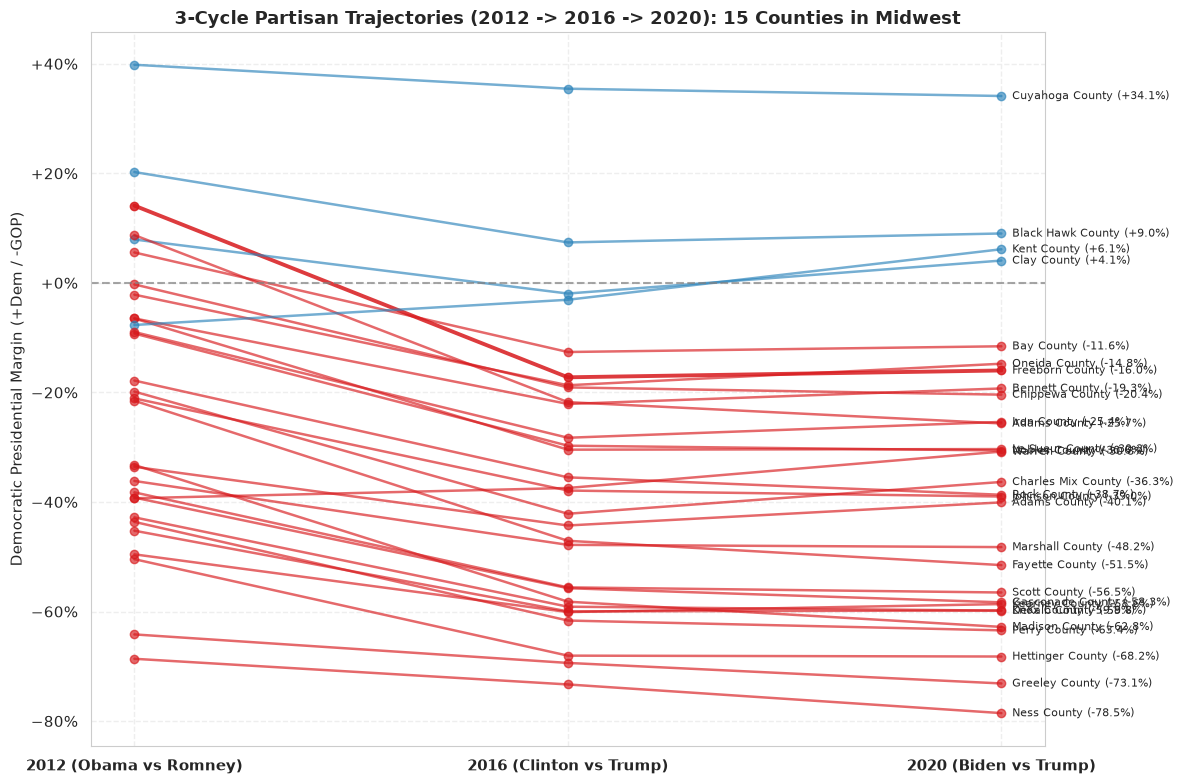

,fips,county_name,state_abbr,archetype_label,pop_2023,median_hh_income,poverty_pct,rucc_code,dem_margin_2020,swing_2012_2020,h3_cell_count
0,27047,Freeborn County,MN,Regional Statistical Centroid (Archetypal Aver...,30515.0,65632.0,11.7,7,-0.160,-0.301,1
1,20117,Marshall County,KS,Intensive Agricultural / Rural Heartland,9933.0,58942.0,10.7,8,-0.482,-0.121,1
2,31001,Adams County,NE,Working-Class Industrial / Post-Industrial Hub,30899.0,64212.0,10.9,4,-0.401,-0.065,1
3,27027,Clay County,MN,University / Higher-Ed Innovation Hub,66258.0,79357.0,11.4,3,0.041,-0.038,1
4,46007,Bennett County,SD,University / Higher-Ed Innovation Hub,3305.0,49152.0,30.7,9,-0.193,-0.128,1
...,...,...,...,...,...,...,...,...,...,...,...
25,20071,Greeley County,KS,Intensive Agricultural / Rural Heartland,1181.0,72300.0,10.3,9,-0.731,-0.090,1
26,29123,Madison County,MO,Persistent-Poverty Distressed Rural,12698.0,47068.0,18.1,9,-0.628,-0.296,1
27,29073,Gasconade County,MO,Swing Bellwether / Polar Pivot County,14705.0,59287.0,14.0,8,-0.583,-0.191,1
28,29157,Perry County,MO,Swing Bellwether / Polar Pivot County,18950.0,63127.0,11.5,6,-0.634,-0.198,1


In [8]:
reg_cohort = cohort_150[cohort_150["macro_region"] == "Midwest"].copy()

# 1. Spatial Biplot
fig_biplot = plot_regional_pca_biplot(gdf_benchmark, reg_cohort, "Midwest")
plt.show()

# 2. Multi-Axis Radar Fingerprint
fig_radar = plot_county_fingerprint_radar(reg_cohort, "Midwest")
plt.show()

# 3. Political Swing Slopegraph (2012 -> 2016 -> 2020)
fig_slope = plot_political_swing_slopegraph(reg_cohort, "Midwest")
plt.show()

# 4. Archetype Profile Table
table_cols = [
    "fips", "county_name", "state_abbr", "archetype_label", 
    "pop_2023", "median_hh_income", "poverty_pct", "rucc_code", 
    "dem_margin_2020", "swing_2012_2020", "h3_cell_count"
]
reg_cohort[table_cols].reset_index(drop=True)

---
## 4. Deep-Dive: The South / Southeast (Appalachia, Deep South & Atlantic) (30 Counties)

Let's explore the 30 selected archetypes for **South / Southeast** through:
1. **Spatial & PCA Biplot**: Where the 30 counties sit in regional geography and latent space.
2. **Multi-Axis Radar Fingerprint**: Comparing contrasting archetypes across 8 dimensions.
3. **Political Swing Trajectory (2012 -> 2016 -> 2020)**: Tracking partisan polarization over 8 years.
4. **Archetype Selection Table**: Comprehensive metric profile for the 30 counties.

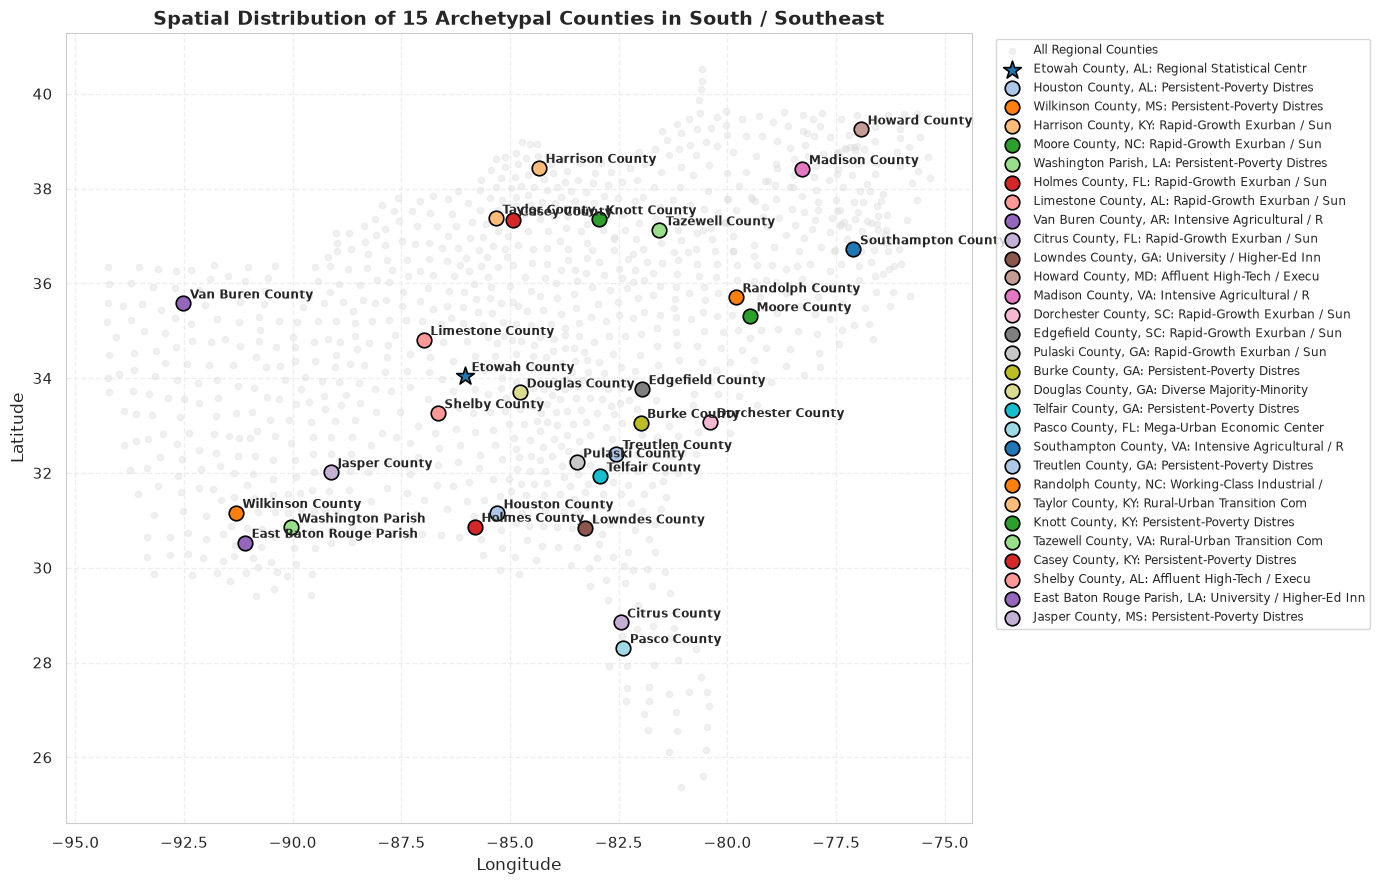

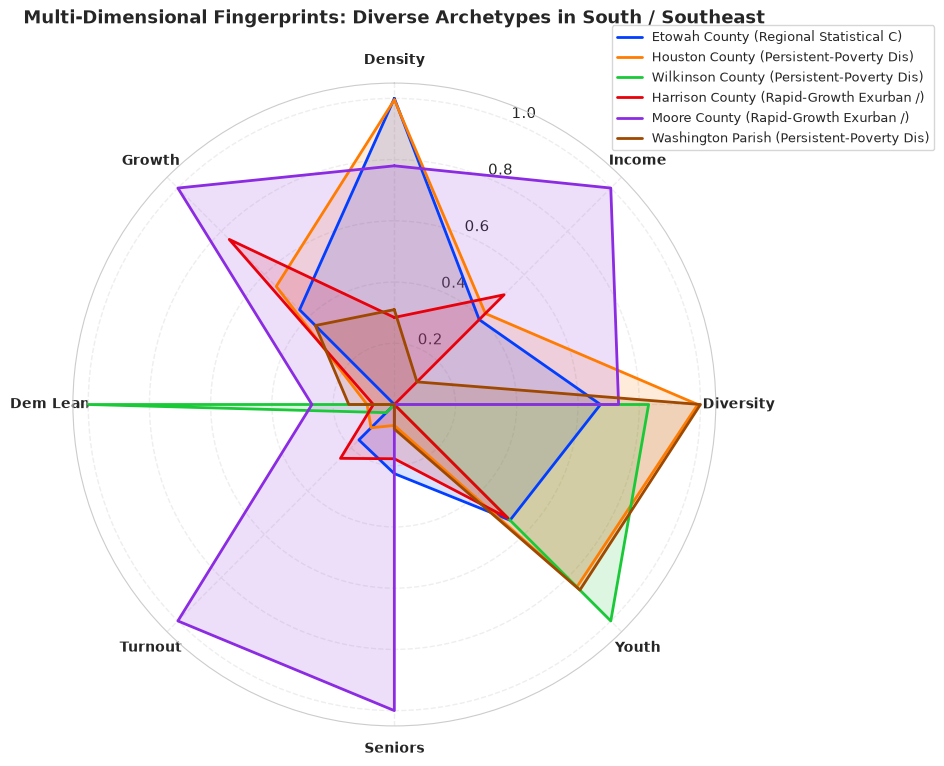

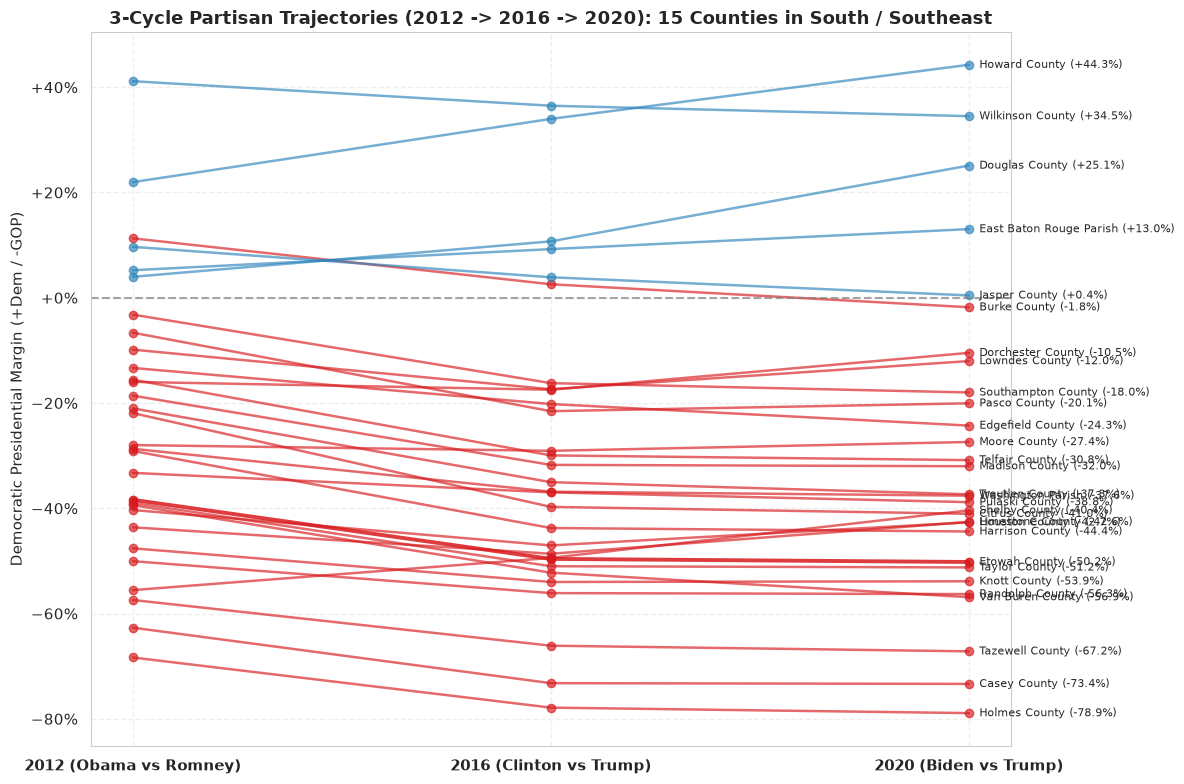

,fips,county_name,state_abbr,archetype_label,pop_2023,median_hh_income,poverty_pct,rucc_code,dem_margin_2020,swing_2012_2020,h3_cell_count
0,01055,Etowah County,AL,Regional Statistical Centroid (Archetypal Aver...,103241.0,55487.0,17.7,3,-0.502,-0.118,1
1,01069,Houston County,AL,Persistent-Poverty Distressed Rural,108462.0,56842.0,17.2,3,-0.427,-0.023,1
2,28157,Wilkinson County,MS,Persistent-Poverty Distressed Rural,8058.0,36798.0,31.3,8,0.345,-0.066,1
3,21097,Harrison County,KY,Rapid-Growth Exurban / Sunbelt Corridor,19415.0,60962.0,14.8,6,-0.444,-0.153,1
4,37125,Moore County,NC,Rapid-Growth Exurban / Sunbelt Corridor,106898.0,84458.0,9.8,3,-0.274,0.006,1
...,...,...,...,...,...,...,...,...,...,...,...
25,51185,Tazewell County,VA,Rural-Urban Transition Community,39120.0,48360.0,17.6,7,-0.672,-0.098,1
26,21045,Casey County,KY,Persistent-Poverty Distressed Rural,15918.0,43539.0,25.5,9,-0.734,-0.107,1
27,01117,Shelby County,AL,Affluent High-Tech / Executive Suburb,233000.0,98263.0,6.8,1,-0.404,0.152,1
28,22033,East Baton Rouge Parish,LA,University / Higher-Ed Innovation Hub,448467.0,61376.0,18.5,2,0.130,0.078,1


In [9]:
reg_cohort = cohort_150[cohort_150["macro_region"] == "South / Southeast"].copy()

# 1. Spatial Biplot
fig_biplot = plot_regional_pca_biplot(gdf_benchmark, reg_cohort, "South / Southeast")
plt.show()

# 2. Multi-Axis Radar Fingerprint
fig_radar = plot_county_fingerprint_radar(reg_cohort, "South / Southeast")
plt.show()

# 3. Political Swing Slopegraph (2012 -> 2016 -> 2020)
fig_slope = plot_political_swing_slopegraph(reg_cohort, "South / Southeast")
plt.show()

# 4. Archetype Profile Table
table_cols = [
    "fips", "county_name", "state_abbr", "archetype_label", 
    "pop_2023", "median_hh_income", "poverty_pct", "rucc_code", 
    "dem_margin_2020", "swing_2012_2020", "h3_cell_count"
]
reg_cohort[table_cols].reset_index(drop=True)

---
## 4. Deep-Dive: Southwest (Texas, Oklahoma, New Mexico, Arizona) (30 Counties)

Let's explore the 30 selected archetypes for **Southwest** through:
1. **Spatial & PCA Biplot**: Where the 30 counties sit in regional geography and latent space.
2. **Multi-Axis Radar Fingerprint**: Comparing contrasting archetypes across 8 dimensions.
3. **Political Swing Trajectory (2012 -> 2016 -> 2020)**: Tracking partisan polarization over 8 years.
4. **Archetype Selection Table**: Comprehensive metric profile for the 30 counties.

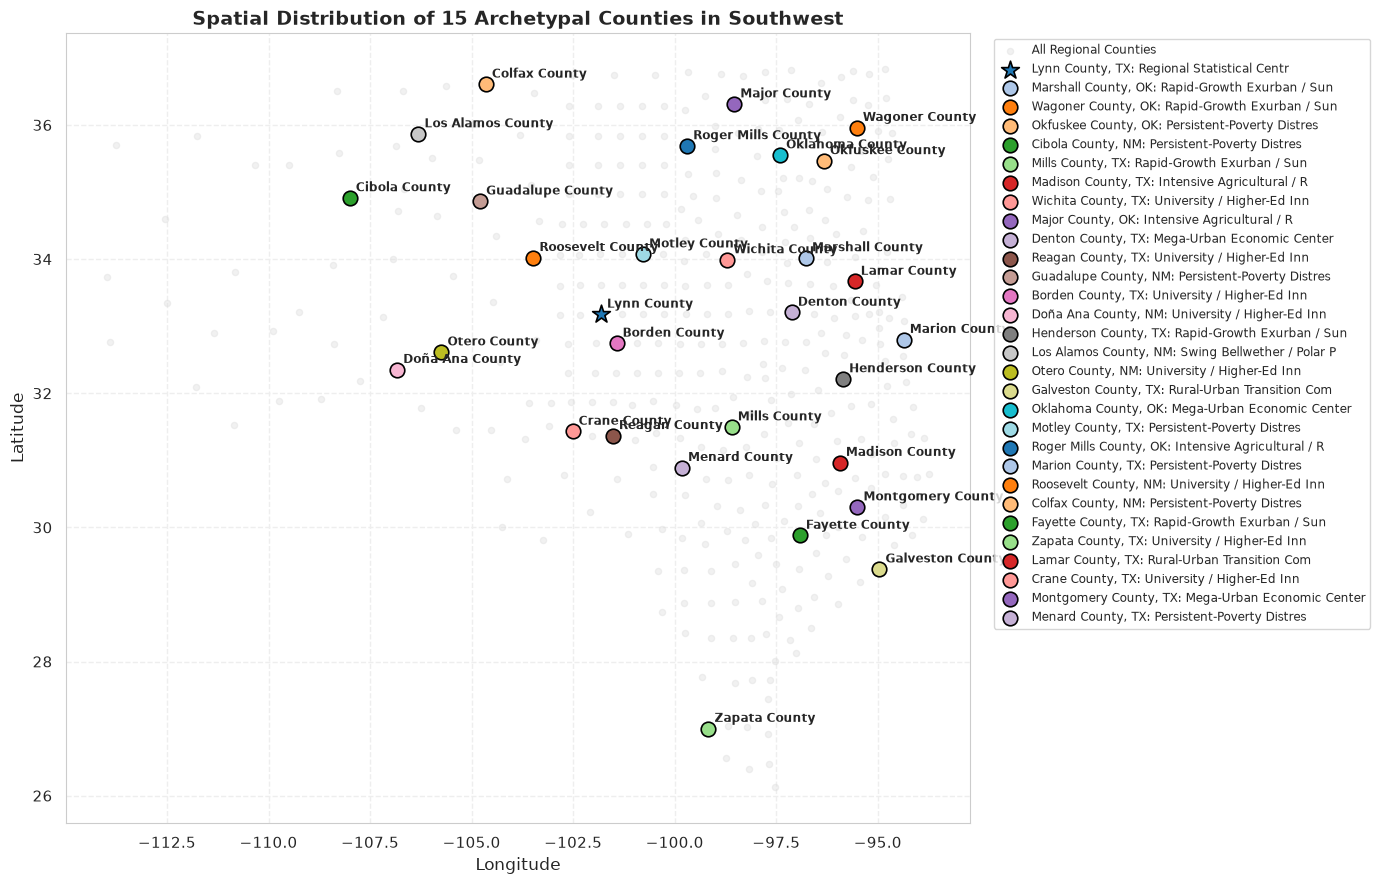

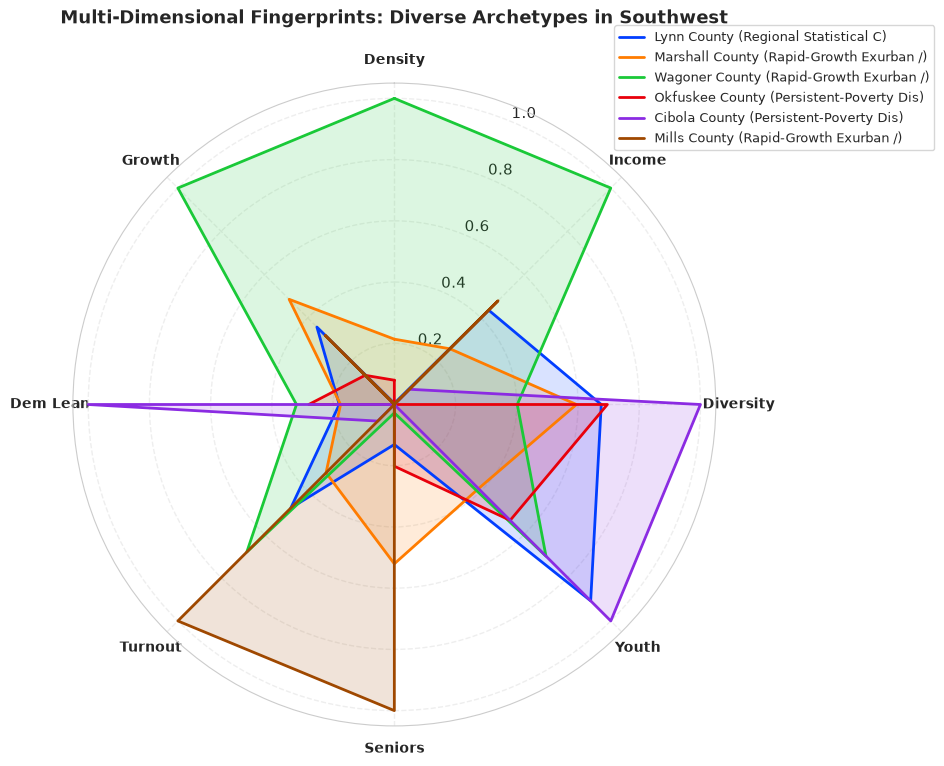

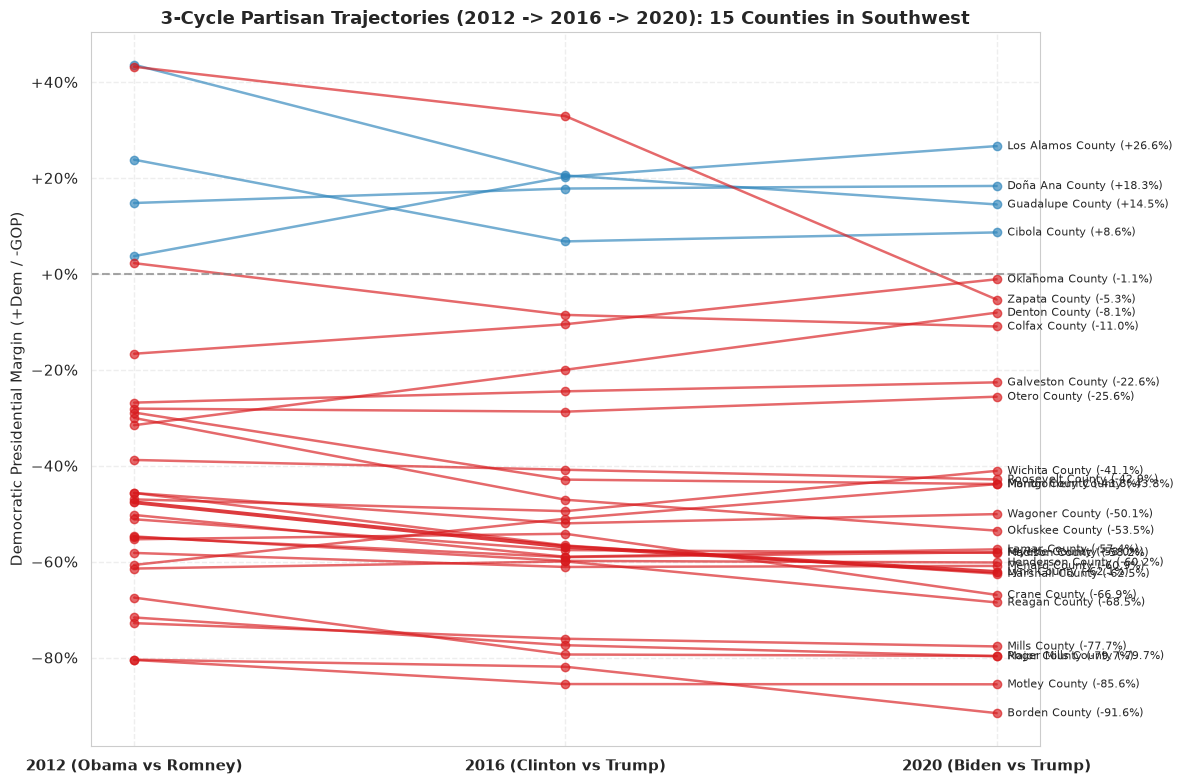

,fips,county_name,state_abbr,archetype_label,pop_2023,median_hh_income,poverty_pct,rucc_code,dem_margin_2020,swing_2012_2020,h3_cell_count
0,48305,Lynn County,TX,Regional Statistical Centroid (Archetypal Aver...,5761.0,56754.0,15.6,2,-0.621,-0.145,1
1,40095,Marshall County,OK,Rapid-Growth Exurban / Sunbelt Corridor,15970.0,51341.0,15.5,9,-0.625,-0.168,1
2,40145,Wagoner County,OK,Rapid-Growth Exurban / Sunbelt Corridor,89280.0,73851.0,9.2,1,-0.501,-0.044,1
3,40107,Okfuskee County,OK,Persistent-Poverty Distressed Rural,11300.0,43544.0,23.8,8,-0.535,-0.235,1
4,35006,Cibola County,NM,Persistent-Poverty Distressed Rural,26780.0,45674.0,29.6,6,0.086,-0.152,1
...,...,...,...,...,...,...,...,...,...,...,...
25,48505,Zapata County,TX,University / Higher-Ed Innovation Hub,13736.0,39403.0,32.8,6,-0.053,-0.485,1
26,48277,Lamar County,TX,Rural-Urban Transition Community,51127.0,62620.0,15.0,5,-0.574,-0.072,1
27,48103,Crane County,TX,University / Higher-Ed Innovation Hub,4574.0,67889.0,11.4,8,-0.669,-0.116,1
28,48339,Montgomery County,TX,Mega-Urban Economic Center,711354.0,95241.0,8.5,1,-0.438,0.168,1


In [10]:
reg_cohort = cohort_150[cohort_150["macro_region"] == "Southwest"].copy()

# 1. Spatial Biplot
fig_biplot = plot_regional_pca_biplot(gdf_benchmark, reg_cohort, "Southwest")
plt.show()

# 2. Multi-Axis Radar Fingerprint
fig_radar = plot_county_fingerprint_radar(reg_cohort, "Southwest")
plt.show()

# 3. Political Swing Slopegraph (2012 -> 2016 -> 2020)
fig_slope = plot_political_swing_slopegraph(reg_cohort, "Southwest")
plt.show()

# 4. Archetype Profile Table
table_cols = [
    "fips", "county_name", "state_abbr", "archetype_label", 
    "pop_2023", "median_hh_income", "poverty_pct", "rucc_code", 
    "dem_margin_2020", "swing_2012_2020", "h3_cell_count"
]
reg_cohort[table_cols].reset_index(drop=True)

---
## 4. Deep-Dive: Northwest (Pacific Northwest, Intermountain West & Alaska) (30 Counties)

Let's explore the 30 selected archetypes for **Northwest** through:
1. **Spatial & PCA Biplot**: Where the 30 counties sit in regional geography and latent space.
2. **Multi-Axis Radar Fingerprint**: Comparing contrasting archetypes across 8 dimensions.
3. **Political Swing Trajectory (2012 -> 2016 -> 2020)**: Tracking partisan polarization over 8 years.
4. **Archetype Selection Table**: Comprehensive metric profile for the 30 counties.

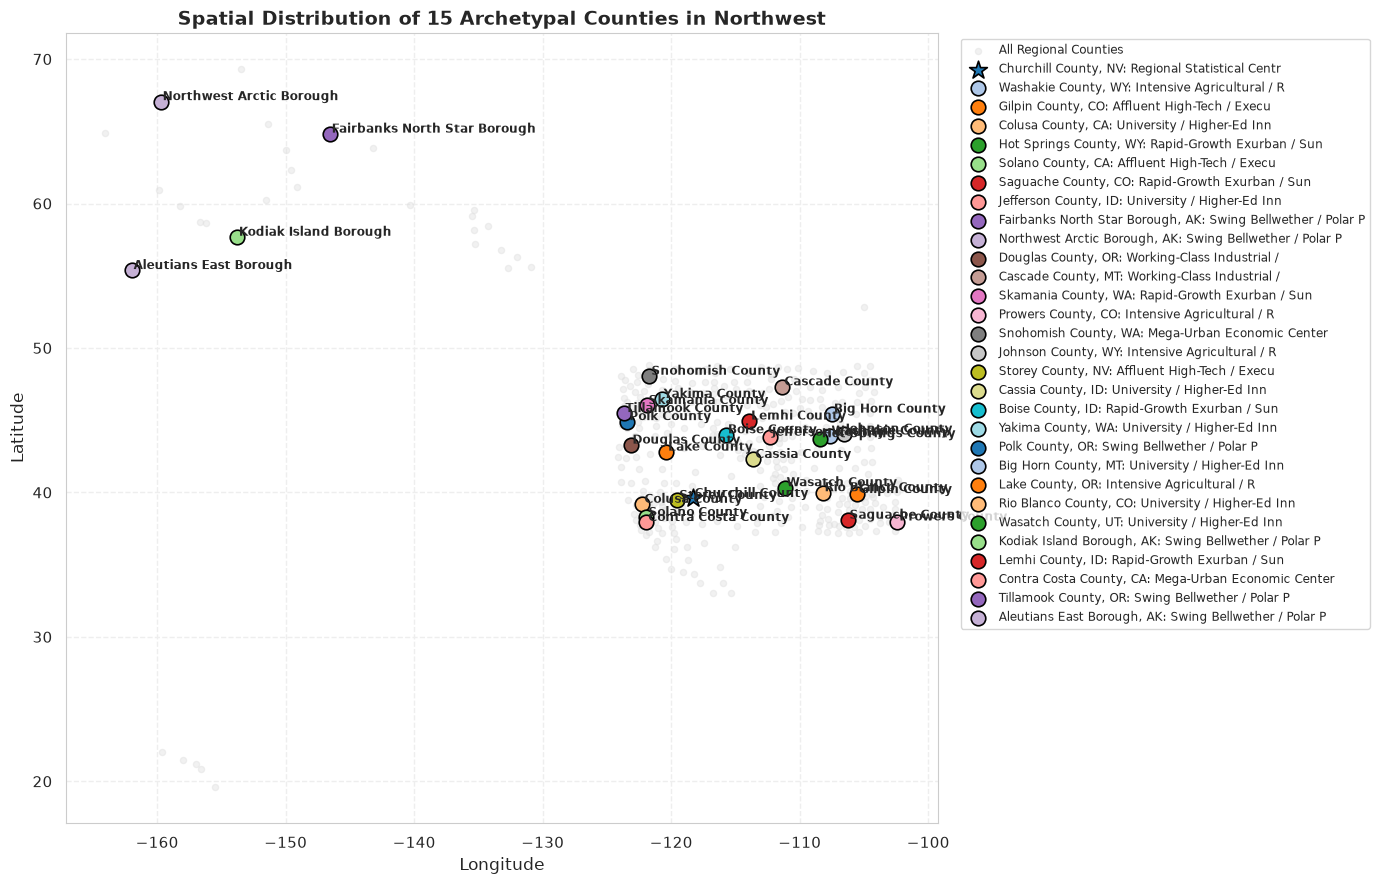

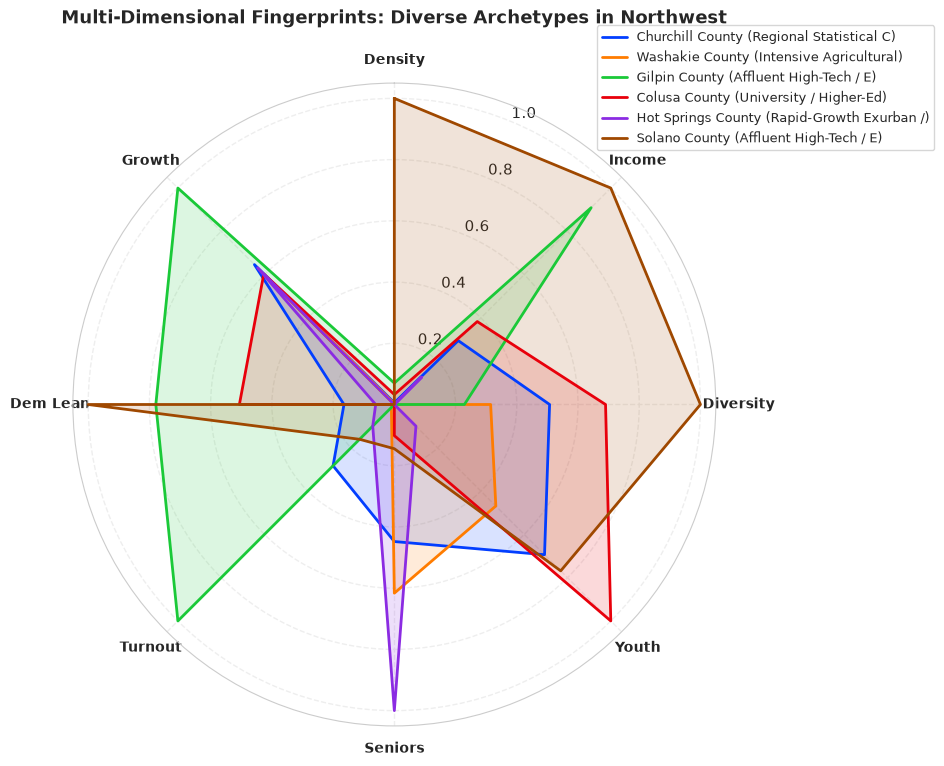

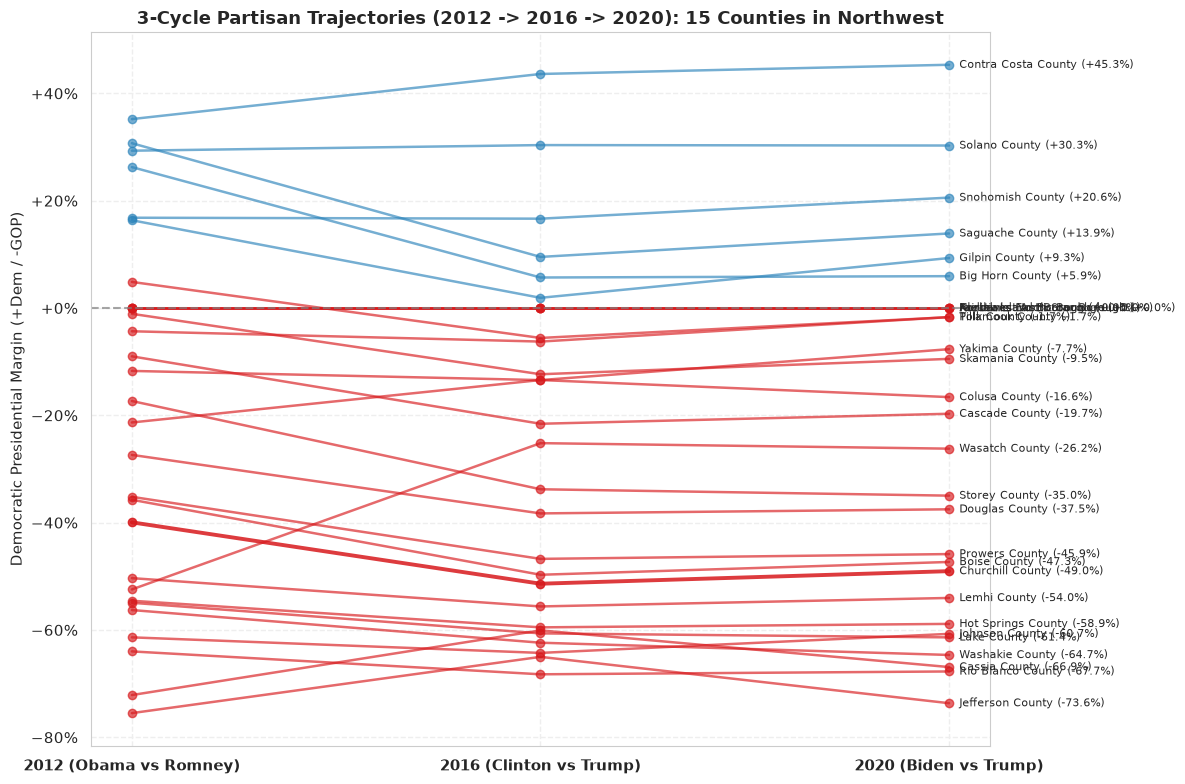

,fips,county_name,state_abbr,archetype_label,pop_2023,median_hh_income,poverty_pct,rucc_code,dem_margin_2020,swing_2012_2020,h3_cell_count
0,32001,Churchill County,NV,Regional Statistical Centroid (Archetypal Aver...,2.580e+04,70149.0,10.1,6,-0.490,-0.091,1
1,56043,Washakie County,WY,Intensive Agricultural / Rural Heartland,7.710e+03,60699.0,10.9,9,-0.647,-0.084,1
2,08047,Gilpin County,CO,Affluent High-Tech / Executive Suburb,5.926e+03,89805.0,6.4,1,0.093,-0.070,1
3,06011,Colusa County,CA,University / Higher-Ed Innovation Hub,2.204e+04,72963.0,10.7,6,-0.166,0.047,1
4,56017,Hot Springs County,WY,Rapid-Growth Exurban / Sunbelt Corridor,4.661e+03,64734.0,12.7,9,-0.589,-0.043,1
...,...,...,...,...,...,...,...,...,...,...,...
25,02150,Kodiak Island Borough,AK,Swing Bellwether / Polar Pivot County,1.256e+04,83222.0,7.5,7,0.000,0.000,1
26,16059,Lemhi County,ID,Rapid-Growth Exurban / Sunbelt Corridor,8.441e+03,55554.0,14.0,9,-0.540,-0.037,1
27,06013,Contra Costa County,CA,Mega-Urban Economic Center,1.155e+06,119667.0,8.7,1,0.453,0.101,1
28,41057,Tillamook County,OR,Swing Bellwether / Polar Pivot County,2.742e+04,64877.0,12.0,7,-0.017,-0.066,1


In [11]:
reg_cohort = cohort_150[cohort_150["macro_region"] == "Northwest"].copy()

# 1. Spatial Biplot
fig_biplot = plot_regional_pca_biplot(gdf_benchmark, reg_cohort, "Northwest")
plt.show()

# 2. Multi-Axis Radar Fingerprint
fig_radar = plot_county_fingerprint_radar(reg_cohort, "Northwest")
plt.show()

# 3. Political Swing Slopegraph (2012 -> 2016 -> 2020)
fig_slope = plot_political_swing_slopegraph(reg_cohort, "Northwest")
plt.show()

# 4. Archetype Profile Table
table_cols = [
    "fips", "county_name", "state_abbr", "archetype_label", 
    "pop_2023", "median_hh_income", "poverty_pct", "rucc_code", 
    "dem_margin_2020", "swing_2012_2020", "h3_cell_count"
]
reg_cohort[table_cols].reset_index(drop=True)

## 5. Master 150-County Cohort Gallery & True Irregular Polygons

We now examine the full nationwide cohort of 150 counties and render their **exact irregular boundary polygons** (not bounding boxes!) on an interactive Folium map.

In [12]:
# Render interactive Folium map with exact irregular cartographic polygons
m = create_interactive_folium_map(cohort_150, output_html="data/processed/cohort_150_interactive_map.html")
print("Interactive map generated with true polygon layers and hover popups.")
m

Interactive map saved to data/processed/cohort_150_interactive_map.html
Interactive map generated with true polygon layers and hover popups.


### Exporting Cohort Metadata for Phase 2 Association Mining

We export the 150-county cohort with:
- True Polygon boundaries (GeoJSON MultiPolygon & WKT)
- Bounding Box envelopes `[min_lon, min_lat, max_lon, max_lat]`
- H3 Polyfill Hexagon cell lists
- Complete demographic, economic, and political baseline metrics

In [13]:
import json

# Export to GeoJSON
export_geojson_path = "data/processed/selected_cohort_150.geojson"
cohort_150_export = cohort_150.copy()
cohort_150_export["h3_cells_str"] = cohort_150_export["h3_cells"].apply(lambda x: ",".join(x))
cohort_150_export.drop(columns=["h3_cells"]).to_file(export_geojson_path, driver="GeoJSON")
print(f"Saved GeoJSON to {export_geojson_path}")

# Also maintain 75 alias
cohort_150_export.drop(columns=["h3_cells"]).to_file("data/processed/selected_cohort_75.geojson", driver="GeoJSON")

# Export to Parquet
export_parquet_path = "data/processed/selected_cohort_150.parquet"
cohort_150_export.to_parquet(export_parquet_path)
cohort_150_export.to_parquet("data/processed/selected_cohort_75.parquet")
print(f"Saved Parquet to {export_parquet_path}")

# Export metadata JSON summary
summary_data = []
for _, row in cohort_150.iterrows():
    summary_data.append({
        "fips": row["fips"],
        "name": row["county_name"],
        "state": row["state_abbr"],
        "macro_region": row["macro_region"],
        "archetype": row["archetype_label"],
        "is_centroid": bool(row["is_regional_centroid"]),
        "pop_2023": int(row["pop_2023"]),
        "median_income": float(row["median_hh_income"]),
        "poverty_pct": float(row["poverty_pct"]),
        "dem_margin_2020": float(row["dem_margin_2020"]),
        "swing_2012_2020": float(row["swing_2012_2020"]),
        "rucc_code": int(row["rucc_code"]),
        "bbox": [float(row["min_lon"]), float(row["min_lat"]), float(row["max_lon"]), float(row["max_lat"])],
        "h3_cell_count": int(row["h3_cell_count"]),
        "h3_sample_cells": row["h3_cells"][:5]
    })

with open("data/processed/selected_cohort_150_summary.json", "w") as f:
    json.dump(summary_data, f, indent=2)
with open("data/processed/selected_cohort_75_summary.json", "w") as f:
    json.dump(summary_data, f, indent=2)
print("Saved cohort summary to data/processed/selected_cohort_150_summary.json")

Saved GeoJSON to data/processed/selected_cohort_150.geojson
Saved Parquet to data/processed/selected_cohort_150.parquet
Saved cohort summary to data/processed/selected_cohort_150_summary.json


---
## Phase 1 Conclusion & Phase 2 Next Steps

The 150 archetypal counties represent ~4.8% of the United States, providing a deep, robust statistical sample across all 5 macro-regions:
- **Urbanization**: Dense mega-cities (Cook IL, Harris TX, King WA, Maricopa AZ, New York NY) down to Frontier wilderness.
- **Wealth Spectrum**: Executive tech corridors (Loudoun VA, Santa Clara CA, Douglas CO) to persistent poverty rural regions.
- **Political Dynamics**: Deep Democratic anchors, solid Republican heartlands, and critical swing bellwethers.

### Ready for Phase 2:
In **Notebook 2**, we iterate over each of these 150 counties, extract bounded slices from the **20 public datasets**, aggregate into the H3 hexagonal grid cells, and mine cross-domain association rules to discover unexpected connections!